# Introduction
After generating our initial set of particles, we now need to simulate their travel through and interaction with our detector. This is done using [Geant4](https://geant4.web.cern.ch/) via [edep-sim](https://github.com/ClarkMcGrew/edep-sim). 

Geant4 provides the physics implementation and internals of the simulation, while edep-sim provides an interface for high-level control and extraction of the results of the simulation.


## Geometry 
Geant4 requires a description of the detector in which to simulate particles. This is done using a `gdml` file. For this example, we'll be using a very simplified version of ProtoDUNE-HD (PDHD): a block of liquid argon with a silicon shell (this is for testing photon detector simulation which is out of scope of this tutorial).

![title](img/geom.png)


The extents of PDHD are roughly:
 - x: (-350, 350) cm
 - y: (0, 600) cm
 - z: (0, 460) cm

For the purposes of this tutorial and given how WireCell uses the geometry in its drift simulation (more on this later), this simplified geometry is all we need: note that the PDHD geometry we actually use in DUNE is much more complicated:

![title](img/full-pdhd.png)




## Outputs
This and the next part of the tutorial will use a special outputting module/format developed while FORM integration was still in development. It uses [HDF5](https://www.hdfgroup.org/solutions/hdf5/) as the file format. FORM is intended to provide an I/O interface with HDF5 at some point in the future, though it will (almost certainly) differ to the structure/format of the output in this tutorial.

While the structure will change, we can learn about how to work with hdf5 with these files. 

# Running edep-sim

Now, rather than simply writing out our HepMC3::GenEvent products, we can start to hook this into later processing stages. We can see how this is done within `transport.jsonnet`. It is broken down as follows


<pre>
{
  /// ---  Same driver as before, but we increase the number of events here
  driver: {
    cpp: 'generate_layers',
    layers: {
      event: { parent: 'job', total: 4, starting_number: 1 },
    },
  },

  /// --- For now, we'll use the simple CCQE generator as the provider
  sources: {
    // Python generator: provides a particle table (creator 'pygen', suffix 'particles')
    pygen: {
      py: 'plugin_generator', ##TODO -- REPLACE THIS WITH THE SKELETON
      layer: 'event',
      # You may add configuration here if you implement that within your generator
    },
  },

  modules: {

    /// --- We still have to convert from the simple 1D table to a HepMC3::GenEvent
    assemble: {
      cpp: 'genevent_from_table',
      input_layer: 'event',
    },

    /// --- This defines the edep-sim portion of the job
    edep_sim_tracking: {
      cpp: 'esp_tracking', /// <--- [module definition](https://github.com/brettviren/edep-sim-phlex/blob/main/modules/tracking.cpp)
      input_layer: 'event',
      gdml: 'gdml/pdhd_like.gdml', /// <--- this is the simple geometry described above 
      macro: '/process/optical/scintillation/setStackPhotons false\n', /// This turns off the CPU-heavy photon simulation
    },

    /// --- This is what we use to properly structure the results of the simulation 
    edep_observables: {
     cpp: 'esp_observables',
     input_layer: 'event',
     input_from: 'edep_sim_tracking',  // consumes the TG4Event from edep_sim_tracking
    },
    
    /// --- Outputting to HDF5
    hdf_out: {
     cpp: 'phlex_arrow_hdf_output',
     output_file: 'obs.h5', 
    },
  },
}
</pre>





In [1]:
! phlex -c transport.jsonnet --stage transport

Using configuration file: transport.jsonnet
[2026-10-28 02:06:23.491] [info] Number of worker threads: 22
[2026-10-28 02:06:23.495] [info] 
[2026-10-28 02:06:23.496] [info] CPU time: 0.00009s  Real time: 0.03753s  CPU efficiency:   0.24%
[2026-10-28 02:06:23.496] [info] Max. RSS: 41.612 MB
Could not locate library with specification 'genevent_from_table' in any directories on PHLEX_PLUGIN_PATH.


## Anaylzing output

Let's take a look at the output now. Remember: this structure is most likely going to change, so I would not recommend using this as a generic reference for the future. Instead, we can look at hdf5 files 




The 3 main levels of hierarchy within HDF5 are Files, Groups, and Datasets.

Datasets are handles to data persisted within the file

Groups provide organizational structure to the file and can hold Datasets and other Groups. 

Files are the highest layer in the format and can hold both Groups and Datasets directly.


Let's start investigating the file:

Import h5py and open the output from the transport step

In [2]:
import h5py as h5
input_file = h5.File('obs.h5', 'r') # 'r' opens it up as read-only 

We can see what is within the file using the keys() method:

In [3]:
input_file.keys()

<KeysViewHDF5 ['event']>

There is a group called 'event' within the file, we can also see what it contains: 

In [4]:
input_file['event'].keys()

<KeysViewHDF5 ['1', '2', '3', '4']>

These correspond to the 4 events we created via phlex.

There happen to be quite a few layers below this, so let's just get to the data i.e. for the first event

In [7]:
for k in input_file['event/1/CURRENT/edep_observables/edep_observables/observables/segments'].keys():
    print(k)

__arrow_schema__
contributors
contributors.__offsets__
energy_deposit
n_electrons
n_photons
pdg
primary_id
sd
secondary_deposit
start_t
start_x
start_y
start_z
stop_t
stop_x
stop_y
stop_z
track_length


This shows various datasets under the 'segments' group which we can start to look at. In this case, a segment refers to a step taken by a particle, during which some energy is deposited. In this implementation, these segments are 'backtracked' up to the primary particle leading to the segment. Still, we can look at the locations of energy deposits and the energy deposited within the segment. 



In [30]:
## To get things working in this env

%config InlineBackend.figure_formats = ['svg']
import matplotlib.pyplot as plt
plt.ioff()

import numpy as np

In python, we can easily refer to an hdf5 group to make things easier to type

In [17]:
segments = input_file['event/4/CURRENT/edep_observables/edep_observables/observables/segments']

Let's look at the positions of energy deposits within our block of liquid argon

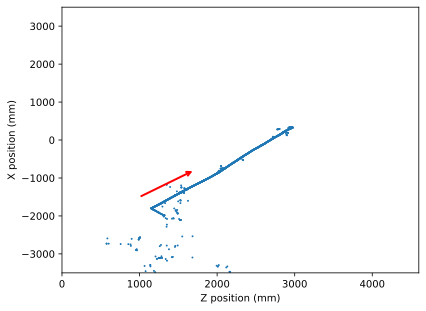

In [46]:
plt.scatter(segments['start_z'], segments['start_x'], s=1.0)
plt.xlim(0,4600)
plt.ylim(-3500, 3500)
plt.xlabel('Z position (mm)')
plt.ylabel('X position (mm)')

# Also drawing an arrow at 45 degrees
ax = plt.gca()
z0, x0 = 1000, -1500              
length_pts = 1000                 
d = length_pts / np.sqrt(2)
ax.annotate('', xy=(z0+d, x0+d), xycoords='data',
            xytext=(z0, x0), textcoords='data',
            arrowprops=dict(arrowstyle='->', color='red', lw=2),
            annotation_clip=False)
plt.show()

We can see a long track pointing almost in the direction of our 45-degree muon.

There is also a short track pointing a little below the horizontal (Z) axis.

These appear to be our muon and proton respectively, but let's double check. Within the segments group is a dataset called 'pdg', which corresponds to the PDG code 

 It doesn't stay at that direction because of interactions with the argon like Multiple Coulomb Scattering.